# Uniaxial Plasticity II

This notebook investigates uniaxial plasticity models that are included in OpenSees/Xara.


In [1]:
#<hide>
try:
    # Try loading a plotting style that may not be installed
    import matplotlib.pyplot as plt
    plt.style.use("thesis")
except:
    pass

For convenience, import unit constants from the {ref}`units` submodule and define parameters.

In [2]:
from xara.units.english import ksi, psi

In [3]:
Fy  =  66.8*ksi           # steel yield stress
Es  = 29000*ksi           # Young modulus of steel

Next, create the {py:class}`xara.UniaxialMaterial`.

In [4]:
import xara 

In [5]:
from numpy import sin, linspace, pi

Now that the stress and strain are stored, the can be plotted using [`matplotlib`](https://matplotlib.org/)

In [6]:
import matplotlib.pyplot as plt

Now create two instances of {ref}`Steel02 <steel02>` with differing values for the `R0` parameter:

In [7]:
parameters = {
    "E": Es,
    "Fy": Fy,
    "R0": 15,
    "b":  0.0,
    "cR1": 0, #0.925,
    "cR2": 0.15,
    "a1": 0.5,
    "a2": 1.0,
    "a3": 0.0,
    "a4": 1.0
}
materials = [
  xara.UniaxialMaterial("Steel02",  **parameters),
#   xara.UniaxialMaterial("Steel2",   **parameters),
  xara.UniaxialMaterial("SteelGPF", **parameters),
  xara.UniaxialMaterial("SteelGPF", **parameters, hardening="PowerRange")
]

## Hardening

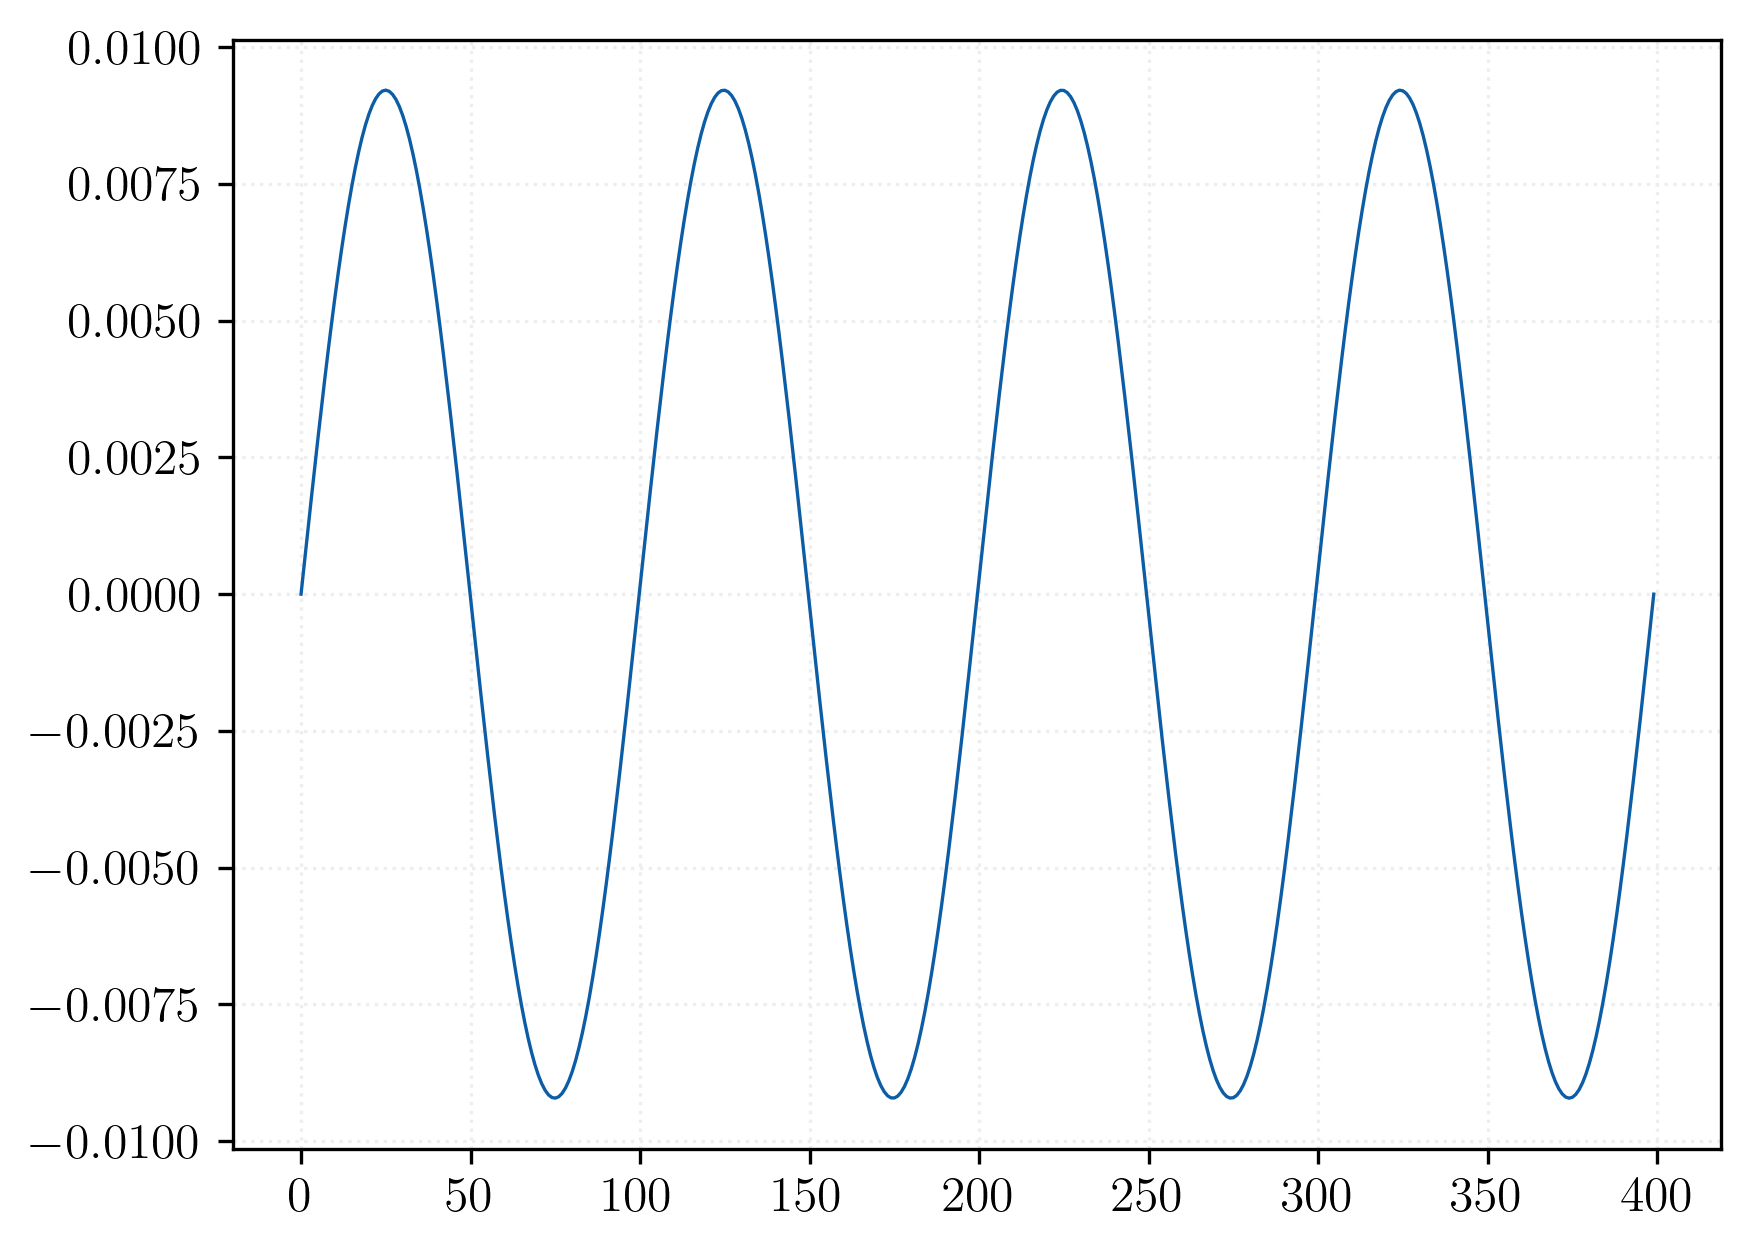

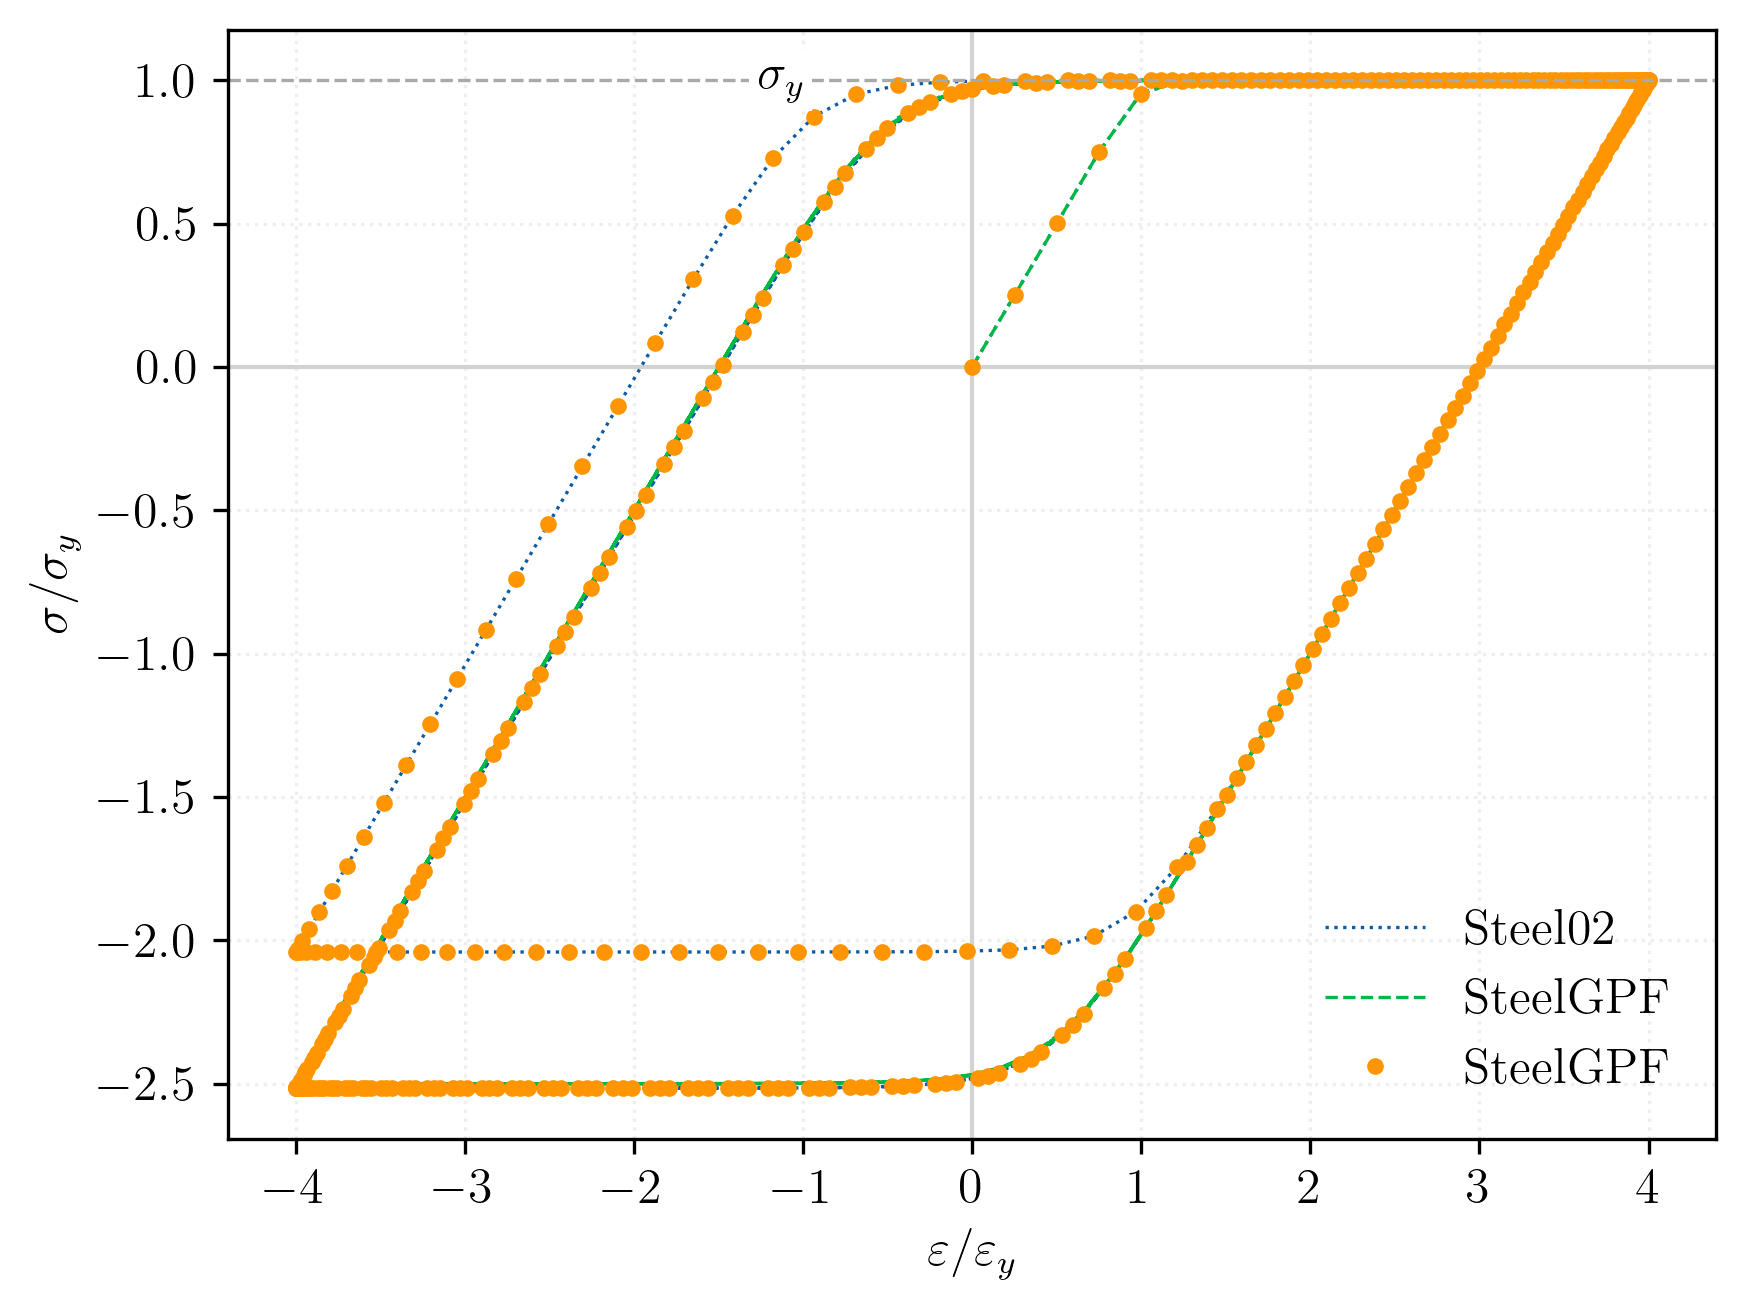

In [8]:
n = 400
strain = (4*Fy/Es)*sin(linspace(0, 8*pi, n))
plt.plot(strain)


Markers = iter([":", "--", ".", "*"])
fig, ax = plt.subplots()
ax.axhline(0, color='lightgrey', linestyle='-', linewidth=1)
ax.axvline(0, color='lightgrey', linestyle='-', linewidth=1)



for material in materials:
    with material as tmp:
        marker = next(Markers)
        ln = ax.plot(strain/(Fy/Es), 
                    [tmp.getStress(e, commit=True)/Fy for e in strain],
                    marker,
                    label=material.type)



# Draw a horizontal line at the yield stress Fy
ax.axhline(y=1, color='darkgrey', linestyle='--')
ax.text(-1, 1, r"$\sigma_y$", color='k', va='center', ha='right', bbox=dict(facecolor='white', edgecolor='none', pad=2.0))

ax.set_xlabel(r"$\varepsilon/\varepsilon_y$")
ax.set_ylabel(r"$\sigma/\sigma_y$")
ax.legend();

## Overshoot

In [9]:
parameters = {
    "E": Es,
    "Fy": Fy,
    "R0": 15,
    "b":  0.05,
    "cR1": 0.925,
    "cR2": 0.15,
    "a1": 0.0,
    "a2": 1.0,
    "a3": 0.0,
    "a4": 1.0
}
materials = [
  xara.UniaxialMaterial("Steel02",  **parameters),
  xara.UniaxialMaterial("Steel2",   **parameters),
  xara.UniaxialMaterial("SteelGPF", **parameters),
  xara.UniaxialMaterial("SteelGPF", **parameters, hardening="PowerRange")
]

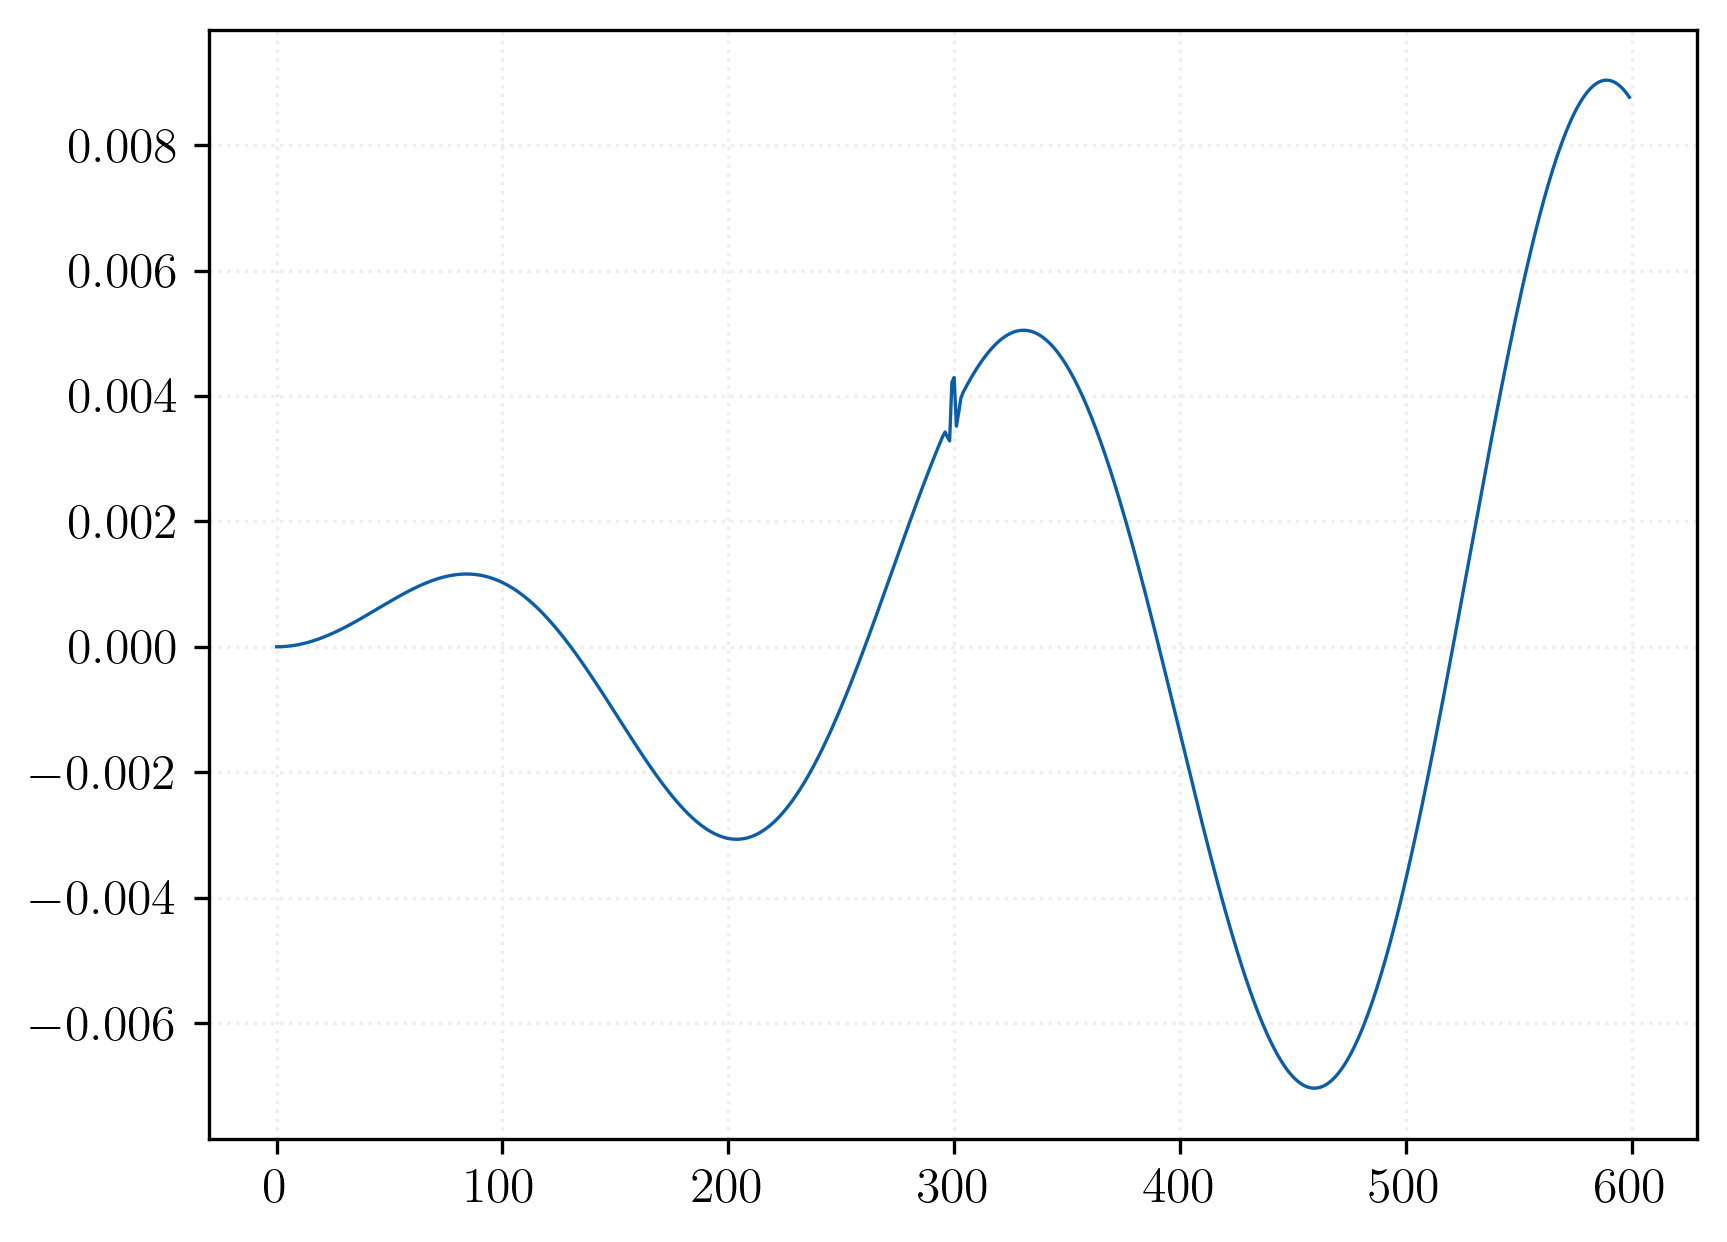

In [10]:
import numpy as np
def ricker(n, a):
    A = 2 / (np.sqrt(3 * a) * (np.pi**0.25))
    wsq = a**2
    vec = np.arange(0, n) - (n - 1.0) / 2
    xsq = vec**2
    mod = (1 - xsq / wsq)
    gauss = np.exp(-xsq / (2 * wsq))
    total = A * mod * gauss
    return total

n = 600
strain = linspace(0, 4*Fy/Es, n)*sin(linspace(0, 4.6*pi, n))
strain += ricker(n, 1.0)*0.4*(Fy/Es)
plt.plot(strain)
# plt.plot(ricker(n, 4.0))

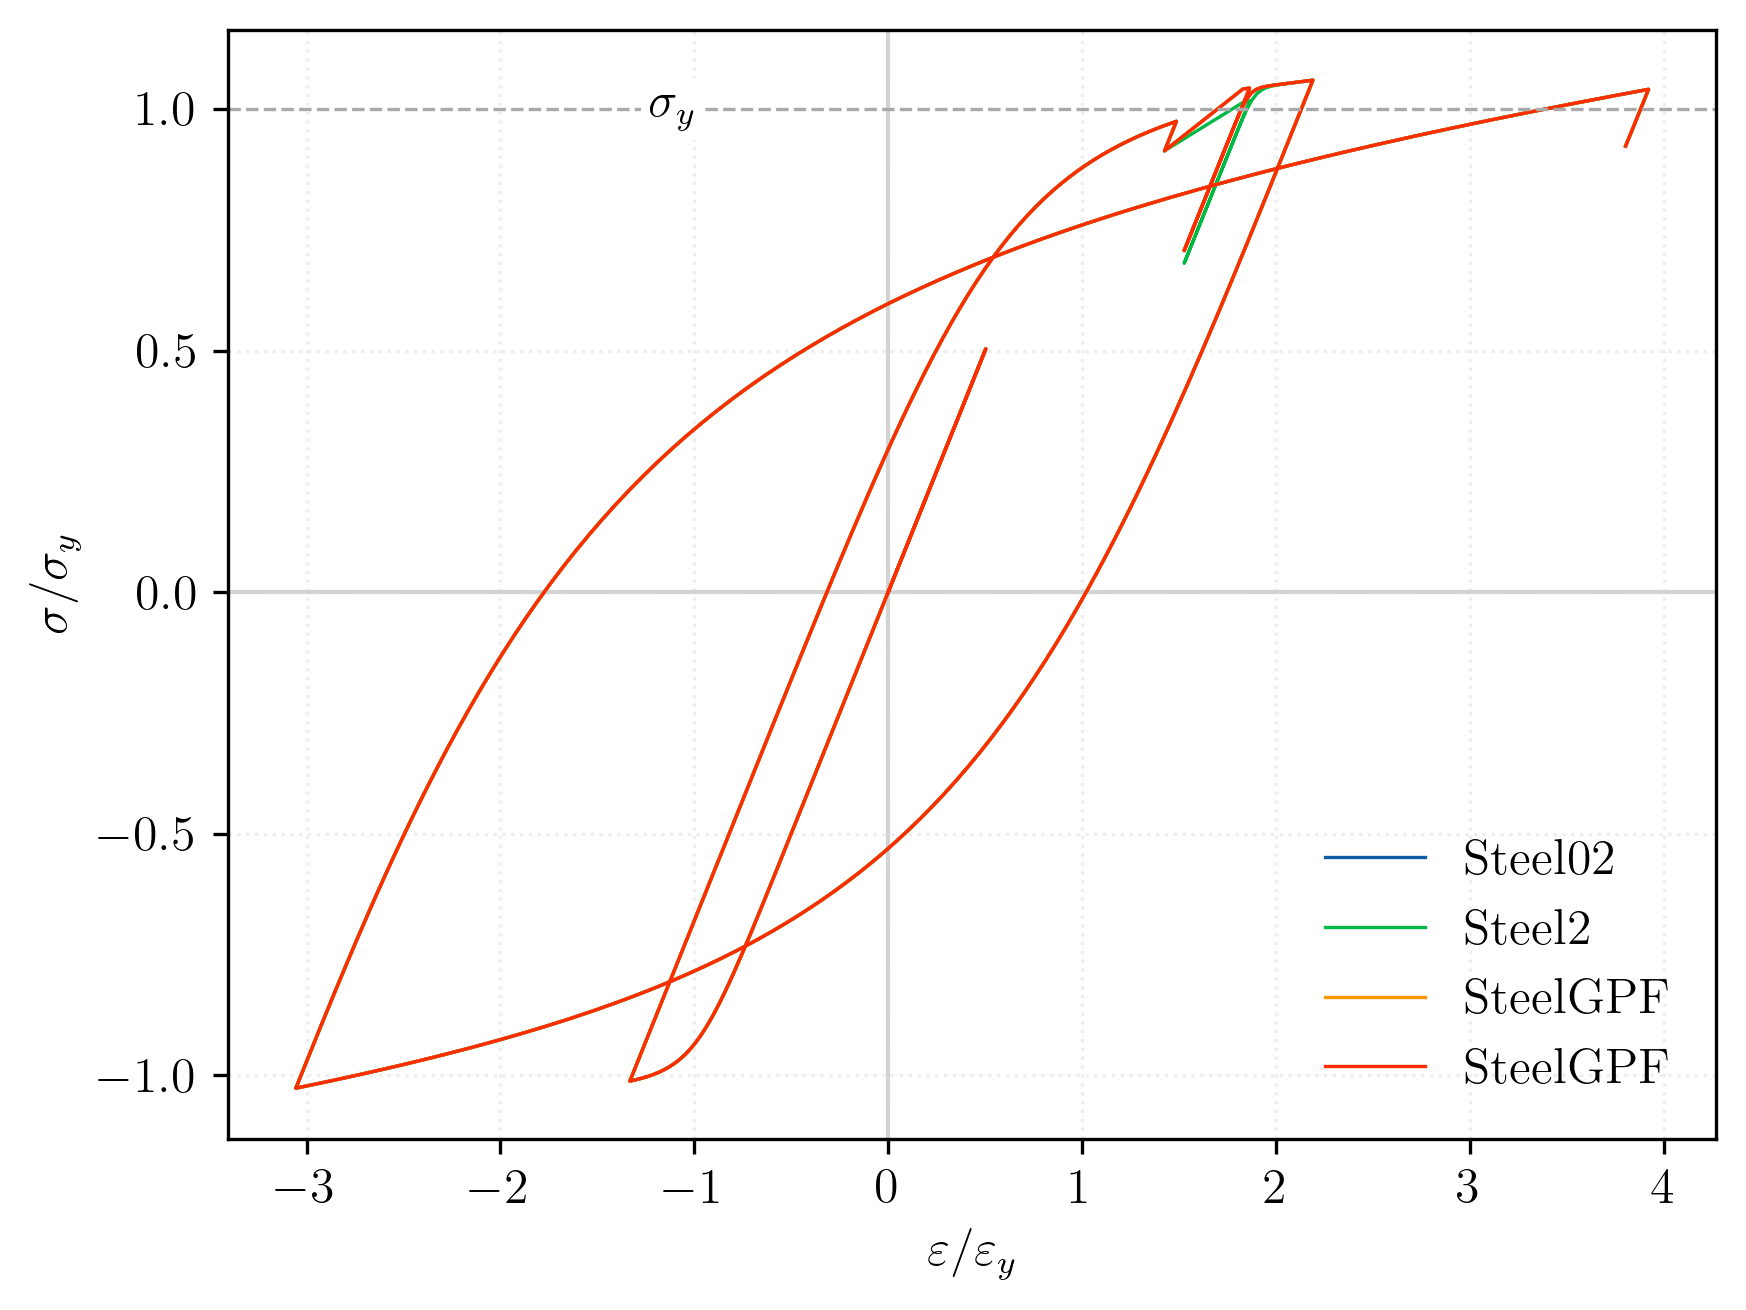

In [11]:
fig, ax = plt.subplots()
ax.axhline(0, color='lightgrey', linestyle='-', linewidth=1)
ax.axvline(0, color='lightgrey', linestyle='-', linewidth=1)



for material in materials:
    with material as tmp:
        ln = ax.plot(strain/(Fy/Es), 
                    [tmp.getStress(e, commit=True)/Fy for e in strain],
                    label=material.type)



# Draw a horizontal line at the yield stress Fy
ax.axhline(y=1, color='darkgrey', linestyle='--')
ax.text(-1, 1, r"$\sigma_y$", color='k', va='center', ha='right', bbox=dict(facecolor='white', edgecolor='none', pad=2.0))

ax.set_xlabel(r"$\varepsilon/\varepsilon_y$")
ax.set_ylabel(r"$\sigma/\sigma_y$")
ax.legend();